<a href="https://colab.research.google.com/github/Preethi-tk/CodeAlpha_Object_Detection_Tracking/blob/main/CodeAlpha_Object_Detection_Tracking.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install ultralytics opencv-python

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 23.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]


In [3]:
from ultralytics import YOLO
import cv2
from IPython.display import display, Image

model = YOLO("yolo11n.pt")

print("YOLO model loaded successfully!")

YOLO model loaded successfully!



image 1/1 /content/bus.jpg: 640x480 4 persons, 1 bus, 407.0ms
Speed: 32.2ms preprocess, 407.0ms inference, 35.9ms postprocess per image at shape (1, 3, 640, 480)


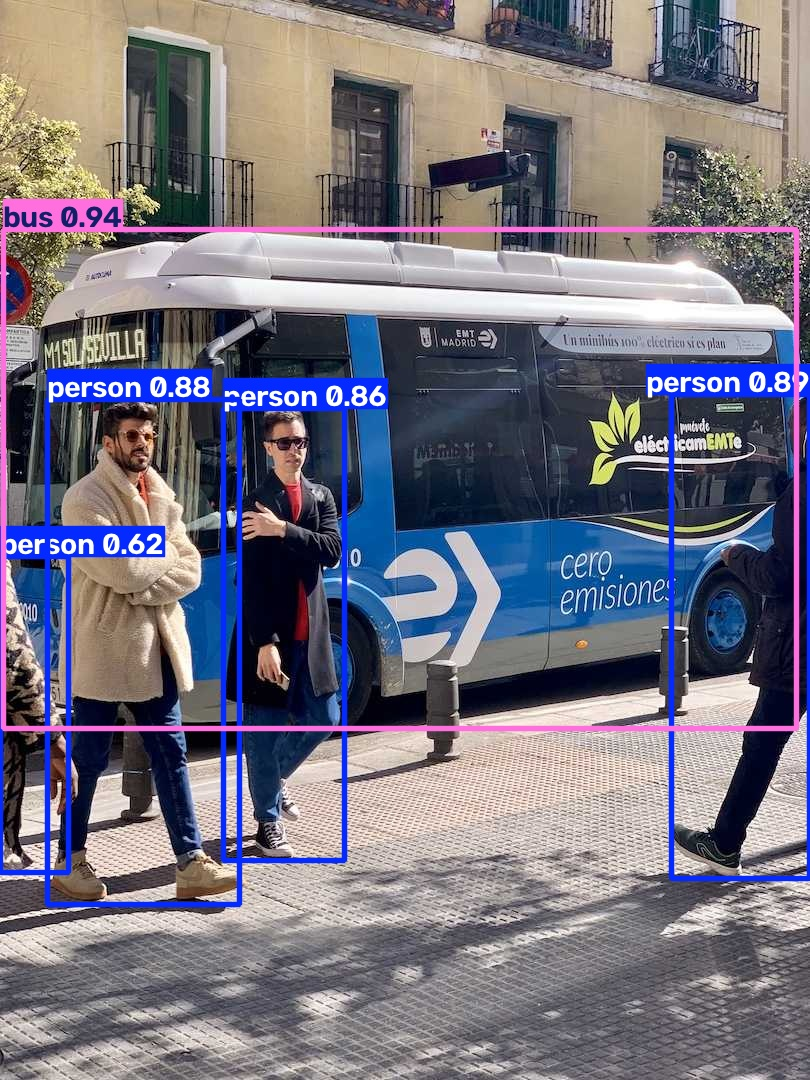

In [4]:
from ultralytics import YOLO
from IPython.display import display, Image

# Download a sample image
!wget -q -O bus.jpg https://ultralytics.com/images/bus.jpg

# Detect objects in the image
results = model.predict(source="bus.jpg", conf=0.25)

# Display the detected image
results[0].save(filename="detected_objects.jpg")
display(Image(filename="detected_objects.jpg"))

In [6]:
# Download a sample video
!wget -O traffic.mp4 https://raw.githubusercontent.com/ultralytics/ultralytics/main/ultralytics/assets/bus.jpg

--2026-10-28 16:12:54--  https://raw.githubusercontent.com/ultralytics/ultralytics/main/ultralytics/assets/bus.jpg
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 137419 (134K) [image/jpeg]
Saving to: ‘traffic.mp4’

traffic.mp4         100%[===================>] 134.20K  --.-KB/s    in 0.02s   

2026-10-28 16:12:54 (6.08 MB/s) - ‘traffic.mp4’ saved [137419/137419]



In [7]:
import requests

url = "https://github.com/intel-iot-devkit/sample-videos/raw/master/people-detection.mp4"

response = requests.get(url, timeout=60)
response.raise_for_status()

with open("traffic.mp4", "wb") as f:
    f.write(response.content)

print("Video downloaded successfully!")
print("File size:", len(response.content), "bytes")

Video downloaded successfully!
File size: 5482579 bytes


In [8]:
results = model.track(
    source="traffic.mp4",
    tracker="bytetrack.yaml",
    conf=0.25,
    save=True
)

print("Object detection and tracking completed!")




WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/596) /content/traffic.mp4: 384x640 (no detections), 137.1ms
video 1/1 (frame 2/596) /content/traffic.mp4: 384x640 (no detections), 118.9ms
video 1/1 (frame 3/596) /content/traffic.mp4: 384x640 (no detections), 114.7ms
video 1/1 (frame 4/596) /content/traffic.mp4: 384x640 (no detections), 115.4ms
video 1/1 (frame 5/596) /content/traffic.mp4: 384x640 (no detections), 115.9ms
video 1/1 (frame 6/596) /content/traffic.mp4: 384x640 (no detect

In [9]:
import glob
import os

videos = glob.glob("runs/detect/track*/**/*.mp4", recursive=True)

if videos:
    print("Tracked video found:", videos[-1])
else:
    print("No tracked video found. Please check Step 4.")

No tracked video found. Please check Step 4.


In [10]:
from IPython.display import Video, display

display(Video(videos[-1], embed=True))

IndexError: list index out of range

In [11]:
import requests

url = "https://raw.githubusercontent.com/intel-iot-devkit/sample-videos/master/people-detection.mp4"

response = requests.get(url, timeout=60)
print("HTTP status:", response.status_code)

if response.status_code == 200 and len(response.content) > 10000:
    with open("traffic.mp4", "wb") as f:
        f.write(response.content)
    print("Video downloaded successfully!")
    print("File size:", len(response.content), "bytes")
else:
    print("Download failed. Please share the output.")

HTTP status: 200
Video downloaded successfully!
File size: 5482579 bytes


In [12]:
# Track objects and save the output video
results = model.track(
    source="traffic.mp4",
    tracker="bytetrack.yaml",
    conf=0.25,
    save=True,
    stream=False
)

print("Object detection and tracking completed!")


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/596) /content/traffic.mp4: 384x640 (no detections), 120.5ms
video 1/1 (frame 2/596) /content/traffic.mp4: 384x640 (no detections), 118.0ms
video 1/1 (frame 3/596) /content/traffic.mp4: 384x640 (no detections), 116.6ms
video 1/1 (frame 4/596) /content/traffic.mp4: 384x640 (no detections), 115.4ms
video 1/1 (frame 5/596) /content/traffic.mp4: 384x640 (no detections), 117.1ms
video 1/1 (frame 6/596) /content/traffic.mp4: 384x640 (no detect

In [ ]:
import os
from IPython.display import Video, display

avi_video = "runs/detect/track/traffic.avi"
mp4_video = "runs/detect/track/traffic_tracked.mp4"

if os.path.exists(avi_video):
    print("Converting AVI to MP4 for browser compatibility...")
    # Convert AVI to H.264 MP4 using ffmpeg
    !ffmpeg -y -i {avi_video} -vcodec libx264 -f mp4 {mp4_video} -loglevel quiet

    if os.path.exists(mp4_video):
        print("Conversion complete! Displaying video:")
        display(Video(mp4_video, embed=True, width=640))
    else:
        print("Conversion failed. Displaying original AVI (may not play in all browsers):")
        display(Video(avi_video, embed=True, width=640))
else:
    print("Target AVI video not found at:", avi_video)

Converting AVI to MP4 for browser compatibility...
